# AE-RL for CICIDS-2017

This notebook adapts the original AE-RL (Adversarial Environment + Reinforcement Learning) setup from NSL-KDD to a more recent IDS dataset (default: **CICIDS-2017**).

**Key changes vs. the original notebook**
- Dataset: CICIDS-2017 (optionally extendable to other tabular IDS datasets).
- Asymmetric agents: **Attacker = DQN** (RL), **Defender = DNN** (supervised classifier).
- Defender explainability: **SHAP** (and optional **SAGE**) feature attributions.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import tensorflow 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import optimizers
from tensorflow.keras import backend as K
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import json
from sklearn.utils import shuffle
import os
import sys
import time

In [2]:
tensorflow.config.list_physical_devices('GPU') 

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [3]:
# Optional: install explainability libraries (run if needed)
# !pip -q install shap sage-importance

import warnings
warnings.filterwarnings('ignore')


In [4]:
# ----------------------------
# Dataset wrapper (CICIDS-2017)
# ----------------------------
# This replaces the original NSL-KDD formatter with a CICIDS-2017 loader.
# Expected raw data: one or more CICIDS-2017 CSVs in `data_dir` (e.g., Monday-WorkingHours.pcap_ISCX.csv, etc.)
#
# Notes:
# - CICIDS-2017 includes identifier/time columns (Flow ID, IPs, Timestamp). We drop non-numeric columns by default.
# - Some columns contain inf/NaN. We clean them before training.
# - The adversarial environment here samples ONLY attack rows (to match the original AE-RL design).
#   Set `include_benign=True` if you want to include BENIGN rows for defender training/evaluation.

from glob import glob
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def _cicids_label_to_type(lbl: str) -> str:
    """Map CICIDS-2017 fine-grained labels into coarser attack-type groups."""
    l = str(lbl).strip().lower()
    # Common CICIDS-2017 labels
    if l == 'benign':
        return 'BENIGN'
    if 'ddos' in l:
        return 'DDoS'
    if 'portscan' in l:
        return 'PortScan'
    if 'bot' in l:
        return 'Bot'
    if 'infiltration' in l:
        return 'Infiltration'
    if 'heartbleed' in l:
        return 'Heartbleed'
    if 'web attack' in l or 'xss' in l or 'sql injection' in l:
        return 'WebAttack'
    if 'patator' in l or 'brute force' in l or 'ssh' in l or 'ftp' in l:
        return 'BruteForce'
    if 'dos' in l:
        return 'DoS'
    # Fallback
    return 'OtherAttack'

class data_cls:
    def __init__(self, train_test, **kwargs):
        self.index = 0
        self.loaded = False
        self.train_test = train_test

        # Dataset selection
        self.dataset = kwargs.get('dataset', 'cicids2017').lower()
        self.data_dir = kwargs.get('data_dir', 'C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/cicids2017/')
        self.label_col = kwargs.get('label_col', 'Label')

        # Where to save preprocessed, one-hot formatted data
        self.formated_train_path = kwargs.get('formated_train_path', 'formated_train_cicids2017_adv.csv')
        self.formated_test_path  = kwargs.get('formated_test_path',  'formated_test_cicids2017_adv.csv')

        # Behavior knobs
        self.test_size = float(kwargs.get('test_size', 0.2))
        self.random_state = int(kwargs.get('random_state', 42))
        self.include_benign = bool(kwargs.get('include_benign', False))  # env sampling is attacks-only by default
        self.force_reformat = bool(kwargs.get('force_reformat', False))

        # Attack-type bookkeeping (used by AE-RL)
        self.attack_map = {}     # fine label -> coarse type
        self.all_attack_names = []  # list of fine labels (attack names)
        self.attack_names = []   # attack names present in the chosen split (train/test)
        self.attack_types = []   # coarse types (defender action space)

        # Format or load cached formatted data
        self._ensure_formatted()

    def _ensure_formatted(self):
        # If formatted files already exist and we are not forcing a rebuild,
        # we still need to reconstruct label metadata (all_attack_names, attack_map, attack_types)
        # because these are not stored inside the CSVs.
        if (not self.force_reformat) and os.path.exists(self.formated_train_path) and os.path.exists(self.formated_test_path):
            # Infer possible label columns from formatted CSV headers by using the CICIDS label->type mapper.
            try:
                cols = pd.read_csv(self.formated_train_path, nrows=0).columns.tolist()
            except Exception:
                cols = pd.read_csv(self.formated_test_path, nrows=0).columns.tolist()

            inferred_labels = [c for c in cols if _cicids_label_to_type(c) != 'OtherAttack']
            # Populate metadata so downstream code can work with cached files.
            self.all_attack_names = sorted(inferred_labels)
            self.attack_map = {lbl: _cicids_label_to_type(lbl) for lbl in self.all_attack_names}
            self.attack_types = sorted(list({self.attack_map[lbl] for lbl in self.all_attack_names}))
            return  # cached

        if self.dataset != 'cicids2017':
            raise ValueError(f"Unsupported dataset='{self.dataset}'. Only 'cicids2017' is implemented here.")

        csv_files = sorted(glob(os.path.join(self.data_dir, "*.csv")))
        if len(csv_files) == 0:
            raise FileNotFoundError(
                f"No CSVs found in data_dir='{self.data_dir}'.\n"
                "Download CICIDS-2017 CSVs and place them in this folder (or update data_dir)."
            )

        # Load and concatenate
        df_list = []
        for fp in csv_files:
            try:
                df_list.append(pd.read_csv(fp, low_memory=False))
            except Exception as e:
                print(f"Skipping {fp} due to read error: {e}")
        df = pd.concat(df_list, ignore_index=True)

        # Normalize column names
        df.columns = [c.strip() for c in df.columns]

        if self.label_col not in df.columns:
            # Common alternative naming
            if 'label' in [c.lower() for c in df.columns]:
                for c in df.columns:
                    if c.lower() == 'label':
                        self.label_col = c
                        break
            else:
                raise KeyError(f"Could not find label column '{self.label_col}' in CICIDS data.")

        # Clean: drop non-numeric identifier columns (keep only numeric features)
        non_feature_cols = set([self.label_col])
        for c in df.columns:
            cl = c.lower()
            if cl in ['flow id', 'source ip', 'destination ip', 'timestamp', 'src ip', 'dst ip']:
                non_feature_cols.add(c)

        # Separate labels
        labels_raw = df[self.label_col].astype(str).str.strip()
        # Map fine labels -> coarse types
        coarse_types = labels_raw.apply(_cicids_label_to_type)

        # By default, AE-RL samples only attacks
        if not self.include_benign:
            keep_mask = coarse_types != 'BENIGN'
            df = df.loc[keep_mask].reset_index(drop=True)
            labels_raw = labels_raw.loc[keep_mask].reset_index(drop=True)
            coarse_types = coarse_types.loc[keep_mask].reset_index(drop=True)

        # Build attack maps from fine labels present
        fine_labels = sorted(labels_raw.unique().tolist())
        self.all_attack_names = fine_labels
        self.attack_map = {lbl: _cicids_label_to_type(lbl) for lbl in fine_labels}

        # Build coarse type list (defender action space)
        self.attack_types = sorted(list({self.attack_map[lbl] for lbl in fine_labels}))

        # Build numeric feature frame
        X = df.drop(columns=list(non_feature_cols), errors='ignore').copy()
        # Force numeric; replace inf; fill nan
        X = X.apply(pd.to_numeric, errors='coerce')
        X.replace([np.inf, -np.inf], np.nan, inplace=True)
        X.fillna(0.0, inplace=True)

        # Standardize features (fit on train only later). We'll store raw and scale in split.
        y_fine = labels_raw
        y_coarse = coarse_types

        # Train/test split stratified by coarse type (more stable than fine labels)
        X_train, X_test, yfine_train, yfine_test, ycoarse_train, ycoarse_test = train_test_split(
            X, y_fine, y_coarse, test_size=self.test_size, random_state=self.random_state, stratify=y_coarse
        )

        # Standardization
        scaler = StandardScaler()
        X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
        X_test_scaled  = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

        # One-hot encode fine label columns to preserve original AE-RL structure
        def build_formatted(X_scaled: pd.DataFrame, yfine: pd.Series) -> pd.DataFrame:
            out = X_scaled.copy()
            for lbl in fine_labels:
                out[lbl] = (yfine.values == lbl).astype(int)
            return out

        df_train_fmt = build_formatted(X_train_scaled, yfine_train)
        df_test_fmt  = build_formatted(X_test_scaled,  yfine_test)

        df_train_fmt.to_csv(self.formated_train_path, index=False)
        df_test_fmt.to_csv(self.formated_test_path, index=False)

    def get_shape(self):
        if self.loaded is False:
            self._load_df()
        return self.df.shape

    def get_batch(self, batch_size=100):
        if self.loaded is False:
            self._load_df()

        batch = self.df.drop(self.all_attack_names, axis=1)
        labels = self.df[self.all_attack_names]

        if batch_size == 'full':
            return batch, labels

        if (self.index + batch_size) > self.df.shape[0]:
            self.index = 0

        batch = batch[self.index:self.index + batch_size]
        labels = labels[self.index:self.index + batch_size]
        self.index += batch_size
        return batch, labels

    def get_full(self):
        if self.loaded is False:
            self._load_df()
        labels = self.df[self.attack_names] if len(self.attack_names) > 0 else self.df[self.all_attack_names]
        batch = self.df.drop(self.all_attack_names, axis=1)
        return batch, labels

    def _load_df(self):
        if self.train_test == 'train':
            self.df = pd.read_csv(self.formated_train_path)
        else:
            self.df = pd.read_csv(self.formated_test_path)

        self.index = np.random.randint(0, max(1, self.df.shape[0]-1), dtype=np.int32)
        self.loaded = True

        # Determine which fine labels (attack names) are present in this split
        self.attack_names = []
        for lbl in self.all_attack_names:
            if lbl in self.df.columns and np.sum(self.df[lbl].values) > 0:
                self.attack_names.append(lbl)


In [5]:
# Huber loss function        
def huber_loss(y_true, y_pred, clip_value=1):
    # Huber loss, see https://en.wikipedia.org/wiki/Huber_loss and
    # https://medium.com/@karpathy/yes-you-should-understand-backprop-e2f06eab496b
    # for details.
    assert clip_value > 0.

    x = y_true - y_pred
    if np.isinf(clip_value):
        # Spacial case for infinity since Tensorflow does have problems
        # if we compare `K.abs(x) < np.inf`.
        return .5 * K.square(x)

    condition = K.abs(x) < clip_value
    squared_loss = .5 * K.square(x)
    linear_loss = clip_value * (K.abs(x) - .5 * clip_value)
    if K.backend() == 'tensorflow':
        import tensorflow as tf
        if hasattr(tf, 'select'):
            return tf.select(condition, squared_loss, linear_loss)  # condition, true, false
        else:
            return tf.where(condition, squared_loss, linear_loss)  # condition, true, false
    elif K.backend() == 'theano':
        from theano import tensor as T
        return T.switch(condition, squared_loss, linear_loss)
    else:
        raise RuntimeError('Unknown backend "{}".'.format(K.backend()))

# Needed for keras huber_loss locate
import tensorflow.keras.losses
tensorflow.keras.losses.huber_loss = huber_loss


In [6]:
class QNetwork():
    """
    Q-Network Estimator
    Represents the global model for the table
    """

    def __init__(self,obs_size,num_actions,hidden_size = 100,
                 hidden_layers = 1,learning_rate=.2):
        """
        Initialize the network with the provided shape
        """
        self.obs_size = obs_size
        self.num_actions = num_actions
        
        # Network arquitecture
        self.model = Sequential()
        # Add imput layer
        self.model.add(Dense(hidden_size, input_shape=(obs_size,),
                             activation='relu'))
        # Add hidden layers
        for layers in range(hidden_layers):
            self.model.add(Dense(hidden_size, activation='relu'))
        # Add output layer    
        self.model.add(Dense(num_actions))
        
        #optimizer = optimizers.SGD(learning_rate)
        # optimizer = optimizers.Adam(alpha=learning_rate)
        optimizer = optimizers.Adam(0.00025)
        # optimizer = optimizers.RMSpropGraves(learning_rate, 0.95, self.momentum, 1e-2)
        
        self.model.compile(
            optimizer=tensorflow.keras.optimizers.Adam(learning_rate=learning_rate),
            loss=tensorflow.keras.losses.Huber(delta=1),
        )

    def predict(self,state,batch_size=1):
        """
        Predicts action values.
        """
        return self.model.predict(state,batch_size=batch_size)

    def update(self, states, q):
        """
        Updates the estimator with the targets.

        Args:
          states: Target states
          q: Estimated values

        Returns:
          The calculated loss on the batch.
        """
        loss = self.model.train_on_batch(states, q)
        return loss
    
    def copy_model(model):
        """Returns a copy of a keras model."""
        model.save('tmp_model.keras')
        return tensorflow.keras.models.load_model('tmp_model.keras', custom_objects={"huber_loss": huber_loss})


In [7]:
#Policy interface
class Policy:
    def __init__(self, num_actions, estimator):
        self.num_actions = num_actions
        self.estimator = estimator
    
class Epsilon_greedy(Policy):
    def __init__(self,estimator ,num_actions ,epsilon,min_epsilon,decay_rate, epoch_length):
        Policy.__init__(self, num_actions, estimator)
        self.name = "Epsilon Greedy"
        
        if (epsilon is None or epsilon < 0 or epsilon > 1):
            print("EpsilonGreedy: Invalid value of epsilon", flush = True)
            sys.exit(0)
        self.epsilon = epsilon
        self.min_epsilon = min_epsilon
        self.actions = list(range(num_actions))
        self.step_counter = 0
        self.epoch_length = epoch_length
        self.decay_rate = decay_rate
        
        #if epsilon is up 0.1, it will be decayed over time
        if self.epsilon > 0.01:
            self.epsilon_decay = True
        else:
            self.epsilon_decay = False
    
    def get_actions(self,states):
        # get next action
        if np.random.rand() <= self.epsilon:
            actions = np.random.randint(0, self.num_actions,states.shape[0])
        else:
            self.Q = self.estimator.predict(states,states.shape[0])
            actions = []
            for row in range(self.Q.shape[0]):
                best_actions = np.argwhere(self.Q[row] == np.amax(self.Q[row]))
                actions.append(best_actions[np.random.choice(len(best_actions))].item())
            
        self.step_counter += 1 
        # decay epsilon after each epoch
        if self.epsilon_decay:
            if self.step_counter % self.epoch_length == 0:
                self.epsilon = max(self.min_epsilon, self.epsilon * self.decay_rate**self.step_counter)
            
        return actions

In [8]:
# class ReplayMemory(object):
#     """Implements basic replay memory"""

#     def __init__(self, observation_size, max_size):
#         self.observation_size = observation_size
#         self.num_observed = 0
#         self.max_size = max_size
#         self.samples = {
#                  'obs'      : np.zeros(self.max_size * 1 * self.observation_size,
#                                        dtype=np.float32).reshape(self.max_size,self.observation_size),
#                  'action'   : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
#                  'reward'   : np.zeros(self.max_size * 1).reshape(self.max_size, 1),
#                  'terminal' : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
#                }

#     # def observe(self, state, action, reward, done):
#     #     index = self.num_observed % self.max_size
#     #     self.samples['obs'][index, :] = state
#     #     self.samples['action'][index, :] = action
#     #     self.samples['reward'][index, :] = reward
#     #     self.samples['terminal'][index, :] = done

#     #     self.num_observed += 1

#     def observe(self, state, action, reward, done):
#             # Convert DataFrame -> ndarray
#         if isinstance(state, pd.DataFrame):
#             state = state.to_numpy()
    
#         state = np.asarray(state)
#         action = np.asarray(action)
    
#         # If batch of states, insert each transition
#         if state.ndim == 2:
#             n = state.shape[0]
    
#             # Make reward/done arrays length n
#             if np.isscalar(reward):
#                 reward = np.full((n,), reward, dtype=np.float32)
#             else:
#                 reward = np.asarray(reward).reshape(-1)
    
#             if np.isscalar(done):
#                 done = np.full((n,), done, dtype=np.float32)
#             else:
#                 done = np.asarray(done).reshape(-1)
    
#             # Make action length n (if scalar, repeat; if already length n, keep)
#             if action.ndim == 0:
#                 action = np.full((n,), action, dtype=np.int64)
#             else:
#                 action = action.reshape(-1)
    
#             # Push each row
#             for s, a, r, d in zip(state, action, reward, done):
#                 self.observe(s, a, r, d)
#             return
    
#     def sample_minibatch(self, minibatch_size):
#         max_index = min(self.num_observed, self.max_size) - 1
#         if max_index <= 0:
#             raise ValueError(f"Not enough samples to draw minibatch yet. num_observed={self.num_observed}")
    
#         sampled_indices = np.random.randint(0, max_index, size=minibatch_size)

#         s      = np.asarray(self.samples['obs'][sampled_indices, :], dtype=np.float32)
#         s_next = np.asarray(self.samples['obs'][sampled_indices+1, :], dtype=np.float32)

#         a      = self.samples['action'][sampled_indices].reshape(minibatch_size)
#         r      = self.samples['reward'][sampled_indices].reshape((minibatch_size, 1))
#         done   = self.samples['terminal'][sampled_indices].reshape((minibatch_size, 1))

#         return (s, a, r, s_next, done)

In [9]:
class ReplayMemory(object):
    """Replay memory storing full transitions: (s, a, r, s', done)."""

    def __init__(self, observation_size, max_size):
        self.observation_size = int(observation_size)
        self.max_size = int(max_size)
        self.num_observed = 0

        self.samples = {
            "obs":      np.zeros((self.max_size, self.observation_size), dtype=np.float32),
            "next_obs": np.zeros((self.max_size, self.observation_size), dtype=np.float32),
            "action":   np.zeros((self.max_size, 1), dtype=np.int16),
            "reward":   np.zeros((self.max_size, 1), dtype=np.float32),
            "terminal": np.zeros((self.max_size, 1), dtype=np.int16),
        }

    def _to_2d_state(self, x):
        # DataFrame -> ndarray
        if isinstance(x, pd.DataFrame):
            x = x.to_numpy()
        x = np.asarray(x, dtype=np.float32)
        if x.ndim == 1:
            x = x.reshape(1, -1)
        return x

    def _to_1d(self, x):
        x = np.asarray(x)
        if x.ndim == 0:
            return x.reshape(1)
        return x.reshape(-1)

    def observe(self, state, action, reward, next_state, done):
        """
        Accepts single OR batched transitions.
        state / next_state can be (obs,), (N, obs) or pd.DataFrame.
        action can be scalar or (N,)
        reward can be scalar or (N,) or (N,1)
        done can be scalar or (N,) or (N,1)
        """
        s  = self._to_2d_state(state)
        ns = self._to_2d_state(next_state)

        if s.shape[1] != self.observation_size or ns.shape[1] != self.observation_size:
            raise ValueError(
                f"obs_size mismatch: expected {self.observation_size}, got {s.shape[1]} and {ns.shape[1]}"
            )

        n = s.shape[0]

        a = self._to_1d(action)
        r = self._to_1d(reward)
        d = self._to_1d(done)

        # Broadcast scalars / singletons to batch length n if needed
        if a.size == 1 and n > 1:
            a = np.full((n,), int(a[0]), dtype=np.int64)
        if r.size == 1 and n > 1:
            r = np.full((n,), float(r[0]), dtype=np.float32)
        if d.size == 1 and n > 1:
            d = np.full((n,), int(d[0]), dtype=np.int64)

        # Final sanity check
        if a.shape[0] != n or r.shape[0] != n or d.shape[0] != n:
            raise ValueError(f"Batch length mismatch: n={n}, action={a.shape}, reward={r.shape}, done={d.shape}")

        # Insert each row as its own transition
        for i in range(n):
            idx = self.num_observed % self.max_size
            self.samples["obs"][idx, :]      = s[i]
            self.samples["next_obs"][idx, :] = ns[i]
            self.samples["action"][idx, 0]   = int(a[i])
            self.samples["reward"][idx, 0]   = float(r[i])
            self.samples["terminal"][idx, 0] = int(d[i])
            self.num_observed += 1

    def sample_minibatch(self, minibatch_size):
        available = min(self.num_observed, self.max_size)
        if available < minibatch_size:
            raise ValueError(
                f"Not enough samples to draw minibatch yet. "
                f"num_observed={self.num_observed}, available={available}, minibatch_size={minibatch_size}"
            )

        sampled_indices = np.random.randint(0, available, size=minibatch_size)

        s      = self.samples["obs"][sampled_indices, :].astype(np.float32)
        s_next = self.samples["next_obs"][sampled_indices, :].astype(np.float32)

        a    = self.samples["action"][sampled_indices].reshape(minibatch_size)          # (mb,)
        r    = self.samples["reward"][sampled_indices].reshape((minibatch_size, 1))     # (mb,1)
        done = self.samples["terminal"][sampled_indices].reshape((minibatch_size, 1))   # (mb,1)

        return (s, a, r, s_next, done)

In [10]:
'''
Reinforcement learning Agent definition
'''

class Agent(object):  
        
    def __init__(self, actions,obs_size, policy="EpsilonGreedy", **kwargs):
        self.actions = actions
        self.num_actions = len(actions)
        self.obs_size = obs_size
        
        self.epsilon = kwargs.get('epsilon', 1)
        self.min_epsilon = kwargs.get('min_epsilon', .1)
        self.gamma = kwargs.get('gamma', .001)
        self.minibatch_size = kwargs.get('minibatch_size', 2)
        self.epoch_length = kwargs.get('epoch_length', 100)
        self.decay_rate = kwargs.get('decay_rate',0.99)
        self.ExpRep = kwargs.get('ExpRep',True)
        if self.ExpRep:
            self.memory = ReplayMemory(self.obs_size, kwargs.get('mem_size', 10))
            #self.memory = ReplayMemory(self.mem_size, self.obs_size)
        
        self.ddqn_time = 100
        self.ddqn_update = self.ddqn_time

        
        self.model_network = QNetwork(self.obs_size, self.num_actions,
                                      kwargs.get('hidden_size', 100),
                                      kwargs.get('hidden_layers',1),
                                      kwargs.get('learning_rate',.2))
        self.target_model_network = QNetwork(self.obs_size, self.num_actions,
                                      kwargs.get('hidden_size', 100),
                                      kwargs.get('hidden_layers',1),
                                      kwargs.get('learning_rate',.2))
        self.target_model_network.model = QNetwork.copy_model(self.model_network.model)
        
        if policy == "EpsilonGreedy":
            self.policy = Epsilon_greedy(self.model_network,len(actions),
                                         self.epsilon,self.min_epsilon,
                                         self.decay_rate,self.epoch_length)
        
        
    def learn(self, states, actions, next_states, rewards, done):
        if self.ExpRep:
            # NOTE: now we store full transitions (s, a, r, s', done)
            self.memory.observe(states, actions, rewards, next_states, done)
        else:
            self.states = states
            self.actions = actions
            self.rewards = rewards
            self.next_states = next_states
            self.done = done
            
    def update_model(self):
        if self.ExpRep:
            (states, actions, rewards, next_states, done) = self.memory.sample_minibatch(self.minibatch_size)
        else:
            states = self.states
            rewards = self.rewards
            next_states = self.next_states
            actions = self.actions
            done = self.done
        
        next_actions = []
        # Compute Q targets
#        Q_prime = self.model_network.predict(next_states,self.minibatch_size)
        Q_prime = self.target_model_network.predict(next_states,self.minibatch_size)
        # TODO: fix performance in this loop
        for row in range(Q_prime.shape[0]):
            best_next_actions = np.argwhere(Q_prime[row] == np.amax(Q_prime[row]))
            next_actions.append(best_next_actions[np.random.choice(len(best_next_actions))].item())
        sx = np.arange(len(next_actions))
        # Compute Q(s,a)
        Q = self.model_network.predict(states,self.minibatch_size)
        # Q-learning update
        # target = reward + gamma * max_a'{Q(next_state,next_action))}
        targets = rewards.reshape(Q[sx,actions].shape) + \
                  self.gamma * Q[sx,next_actions] * \
                  (1-done.reshape(Q[sx,actions].shape))   
        Q[sx,actions] = targets  
        
        loss = self.model_network.model.train_on_batch(states,Q)#inputs,targets        
        
        # timer to ddqn update
        self.ddqn_update -= 1
        if self.ddqn_update == 0:
            self.ddqn_update = self.ddqn_time
#            self.target_model_network.model = QNetwork.copy_model(self.model_network.model)
            self.target_model_network.model.set_weights(self.model_network.model.get_weights()) 
        
        return loss    

    def act(self, state,policy):
        raise NotImplementedError

In [11]:
# ----------------------------
# Agents (Asymmetric pairing)
# ----------------------------
# Defender: Deep Q-Network (RL) -> predicts coarse attack type (defense action)
# Attacker: Deep Neural Network (supervised baseline) -> selects attack label (fine-grained)

from tensorflow.keras.utils import to_categorical

class DefenderDNN(object):
    def __init__(self, obs_size, n_classes, **kwargs):
        self.obs_size = obs_size
        self.n_classes = n_classes
        self.hidden_size = kwargs.get('hidden_size', 128)
        self.hidden_layers = kwargs.get('hidden_layers', 2)
        self.learning_rate = kwargs.get('learning_rate', 1e-3)

        self.model = Sequential()
        self.model.add(Dense(self.hidden_size, input_dim=self.obs_size, activation='relu'))
        for _ in range(self.hidden_layers - 1):
            self.model.add(Dense(self.hidden_size, activation='relu'))
        self.model.add(Dense(self.n_classes, activation='softmax'))

        opt = optimizers.Adam(learning_rate=self.learning_rate)
        self.model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

    def fit(self, X_train, y_train_idx, X_val=None, y_val_idx=None, **kwargs):
        y_train = to_categorical(y_train_idx, num_classes=self.n_classes)
        val_data = None
        if X_val is not None and y_val_idx is not None:
            y_val = to_categorical(y_val_idx, num_classes=self.n_classes)
            val_data = (X_val, y_val)

        epochs = kwargs.get('epochs', 5)
        batch_size = kwargs.get('batch_size', 1024)
        verbose = kwargs.get('verbose', 0)

        return self.model.fit(X_train, y_train, validation_data=val_data,
                              epochs=epochs, batch_size=batch_size, verbose=verbose)

    def act(self, states):
        # states: pd.DataFrame or np.ndarray
        X = states.values if hasattr(states, "values") else states
        probs = self.model.predict(X, verbose=0)
        return np.argmax(probs, axis=1)

    def save(self, json_path, weights_path):
        self.model.save_weights(weights_path, overwrite=True)
        with open(json_path, "w") as f:
            json.dump(self.model.to_json(), f)

    @staticmethod
    def load(json_path, weights_path, **kwargs):
        from tensorflow.keras.models import model_from_json
        with open(json_path, "r") as f:
            model = model_from_json(json.load(f))
        model.load_weights(weights_path)
        # compile for inference / SHAP
        opt = optimizers.Adam(learning_rate=kwargs.get('learning_rate', 1e-3))
        model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
        obj = DefenderDNN(obs_size=1, n_classes=1)  # dummy, will overwrite
        obj.model = model
        return obj


# Alias: reuse the same DNN wrapper for the attacker (fine-grained attack selection)
AttackerDNN = DefenderDNN

class AttackAgent(Agent):
    def __init__(self, actions, obs_size, policy="EpsilonGreedy", **kwargs):
        super().__init__(actions, obs_size, policy="EpsilonGreedy", **kwargs)

    def act(self, states):
        actions = self.policy.get_actions(states)
        return actions


In [12]:
'''
Reinforcement learning Enviroment Definition
'''
class RLenv(data_cls):
    def __init__(self,train_test,**kwargs):
        data_cls.__init__(self,train_test,**kwargs)
        data_cls._load_df(self)
        self.data_shape = data_cls.get_shape(self)
        self.batch_size = kwargs.get('batch_size',1) # experience replay -> batch = 1
        self.iterations_episode = kwargs.get('iterations_episode',10)
        if self.batch_size=='full':
            self.batch_size = int(self.data_shape[0]/iterations_episode)


    '''
    _update_state: function to update the current state
    Returns:
        None
    Modifies the self parameters involved in the state:
        self.state and self.labels
    Also modifies the true labels to get learning knowledge
    '''
    def _update_state(self):        
        self.states,self.labels = data_cls.get_batch(self)
        
        # Update statistics
        self.true_labels += np.sum(self.labels).values

    '''
    Returns:
        + Observation of the enviroment
    '''
    def reset(self):
        # Statistics
        self.def_true_labels = np.zeros(len(self.attack_types),dtype=int)
        self.def_estimated_labels = np.zeros(len(self.attack_types),dtype=int)
        self.att_true_labels = np.zeros(len(self.attack_names),dtype=int)
        
        self.state_numb = 0
        
        data_cls._load_df(self) # Reload and random index
        self.states,self.labels = data_cls.get_batch(self,self.batch_size)
        
        self.total_reward = 0
        self.steps_in_episode = 0
        return self.states 
   
    '''
    Returns:
        State: Next state for the game
        Reward: Actual reward
        done: If the game ends (no end in this case)
    
    In the adversarial enviroment, it's only needed to return the actual reward
    '''    
    def act(self,defender_actions,attack_actions):
        # Clear previous rewards        
        self.att_reward = np.zeros(len(attack_actions))       
        self.def_reward = np.zeros(len(defender_actions))
        
        
        attack = [self.attack_types.index(self.attack_map[self.attack_names[att]]) for att in attack_actions]
        
        self.def_reward = (np.asarray(defender_actions)==np.asarray(attack))*1
        self.att_reward = (np.asarray(defender_actions)!=np.asarray(attack))*1

         
       
        self.def_estimated_labels += np.bincount(defender_actions,minlength=len(self.attack_types))
        # TODO
        # list comprehension
        
        for act in attack_actions:
            self.def_true_labels[self.attack_types.index(self.attack_map[self.attack_names[act]])] += 1
        

        # Get new state and new true values 
        attack_actions = attacker_agent.act(self.states)
        self.states = self.get_states(attack_actions)
        
        # Done allways false in this continuous task       
        self.done = np.zeros(len(attack_actions),dtype=bool)
            
        return self.states, self.def_reward,self.att_reward, attack_actions, self.done
    
    '''
    Provide the actual states for the selected attacker actions
    Parameters:
        self:
        attacker_actions: optimum attacks selected by the attacker
            it can be one of attack_names list and select random of this
    Returns:
        State: Actual state for the selected attacks
    '''
    def get_states(self,attacker_actions):
        first = True
        for attack in attacker_actions:
            if first:
                minibatch = (self.df[self.df[self.attack_names[attack]]==1].sample(1))
                first = False
            else:
                minibatch = pd.concat(
                    [minibatch, self.df[self.df[self.attack_names[attack]] == 1].sample(1)],
                    ignore_index=True
                )
        
        self.labels = minibatch[self.attack_names]
        minibatch.drop(self.all_attack_names,axis=1,inplace=True)
        self.states = minibatch
        
        return self.states



In [13]:
if __name__ == "__main__":

    # ----------------------------
    # 1) Dataset configuration
    # ----------------------------
    # Put CICIDS-2017 CSV files in this folder, or change `data_dir`.
    data_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/cicids2017/"

    formated_train_path = "formated_train_cicids2017_adv.csv"
    formated_test_path  = "formated_test_cicids2017_adv.csv"

    # AE-RL loop settings
    batch_size = 32               # number of flows per "state batch"
    minibatch_size = 256          # replay minibatch size
    ExpRep = True                 # experience replay
    iterations_episode = 100
    n_epochs = 50

    # ----------------------------
    # 1b) Create environment (TRAIN)
    # ----------------------------
    # NOTE: `include_benign=True` avoids empty splits if your folder includes benign-only days.
    env = RLenv(
        'train',
        dataset='cicids2017',
        data_dir=data_dir,
        formated_train_path=formated_train_path,
        formated_test_path=formated_test_path,
        batch_size=batch_size,
        iterations_episode=iterations_episode,
        include_benign=True,
        force_reformat=True,
        test_size=0.2,
        random_state=42
    )

    # obs_size = number of numeric feature columns
    obs_size = env.data_shape[1] - len(env.all_attack_names)

    print(f"Observation size: {obs_size}")
    print(f"Fine-grained attack labels: {len(env.attack_names)}")
    print(f"Coarse attack types (defender actions): {len(env.attack_types)} -> {env.attack_types}")

    # ----------------------------
    # 2) Train Attacker as a DNN (supervised baseline)
    #    - predicts fine-grained attack label (one-hot columns)
    # ----------------------------
    df_train = pd.read_csv(formated_train_path)

    # Determine which one-hot label columns to use.
    # Prefer env.attack_names when available, otherwise infer from the formatted CSV header.
    label_cols = list(getattr(env, "attack_names", [])) if len(getattr(env, "attack_names", [])) > 0 else []
    if len(label_cols) == 0:
        label_cols = [c for c in df_train.columns if _cicids_label_to_type(c) != "OtherAttack"]

    if len(label_cols) == 0:
        raise ValueError(
            "No one-hot label columns were found in the formatted training CSV. "
            "This usually means you formatted only BENIGN data while include_benign=False (e.g., Monday-only CICIDS2017), "
            "or the formatted CSV was created without label columns. "
            "Fix: point data_dir at CSVs that include attacks (Tue–Fri) and rerun with force_reformat=True."
        )

    # Features are everything except the one-hot label columns
    X_np = df_train.drop(label_cols, axis=1, errors="ignore").to_numpy(dtype=np.float32)

    # Integer class indices (0..n_classes-1)
    y_fine = np.argmax(df_train[label_cols].to_numpy(), axis=1).astype(np.int64)

    # Stratified split fails if any class has <2 samples.
    # Put rare classes entirely in TRAIN so the model can still see them.
    counts = np.bincount(y_fine, minlength=len(label_cols))
    rare_classes = np.where(counts < 2)[0]

    if len(rare_classes) > 0:
        print("Rare fine-label classes (kept only in TRAIN):", [(label_cols[i], int(counts[i])) for i in rare_classes])
        rare_mask = counts[y_fine] < 2
        X_common, y_common = X_np[~rare_mask], y_fine[~rare_mask]
        X_rare, y_rare = X_np[rare_mask], y_fine[rare_mask]

        # If there is only one class in y_common, stratify must be disabled.
        strat = y_common if len(np.unique(y_common)) > 1 else None

        X_tr, X_val, y_tr, y_val = train_test_split(
            X_common,
            y_common,
            test_size=0.2,
            random_state=42,
            stratify=strat,
        )

        if len(X_rare) > 0:
            X_tr = np.concatenate([X_tr, X_rare], axis=0)
            y_tr = np.concatenate([y_tr, y_rare], axis=0)
    else:
        X_tr, X_val, y_tr, y_val = train_test_split(
            X_np,
            y_fine,
            test_size=0.2,
            random_state=42,
            stratify=y_fine,
        )

    attacker_dnn = AttackerDNN(
        obs_size=obs_size,
        n_classes=len(label_cols),
        hidden_size=128,
        hidden_layers=2,
        learning_rate=1e-3,
    )

    attacker_dnn.fit(X_tr, y_tr, X_val, y_val, epochs=5, batch_size=256, verbose=1)

    # Legacy alias used inside RLenv.act (older notebooks used `attacker_agent`)
    attacker_agent = attacker_dnn

    # ----------------------------
    # 3) Defender as a DQN (RL)
    #    - actions = coarse attack types (indices into env.attack_types)
    # ----------------------------
    defender_valid_actions = list(range(len(env.attack_types)))

    defender_agent = AttackAgent(
        defender_valid_actions,
        obs_size,
        "EpsilonGreedy",
        epoch_length=iterations_episode,
        epsilon=1.0,
        min_epsilon=0.10,
        decay_rate=0.995,
        gamma=0.001,
        hidden_size=128,
        hidden_layers=2,
        minibatch_size=minibatch_size,
        mem_size=5000,
        learning_rate=2e-4,
    )

    # ----------------------------
    # 4) Adversarial training loop
    # ----------------------------
    def_reward_chain = []
    att_reward_chain = []
    def_loss_chain = []
    att_loss_chain = []   # kept for backward-compat plotting (attacker is DNN now)
    attacks_by_epoch = []

    for epoch in range(n_epochs):
        def_total_reward_by_episode = 0
        att_total_reward_by_episode = 0
        def_loss = 0.0
        att_loss = 0.0

        # Reset environment (random batch of flows)
        states = env.reset()  # pd.DataFrame of features

        # Initial attacker action(s) and environment state update
        # Attacker DNN outputs a fine-grained attack label per row in the state batch
        attack_actions = attacker_dnn.act(states)
        states = env.get_states(attack_actions)

        attacks_list = []

        for i_iteration in range(iterations_episode):
            attacks_list.append(int(np.asarray(attack_actions)[0]))

            # Defender chooses coarse defense action via DQN
            defender_actions = defender_agent.act(states)

            # Environment step: computes rewards and samples next state
            next_states, def_reward, att_reward, next_attack_actions, done = env.act(defender_actions, attack_actions)

            # Defender learns from transition
            defender_agent.learn(states, defender_actions, next_states, def_reward, done)

            # Experience replay update (only when buffer has enough samples)
            if ExpRep and defender_agent.memory.num_observed >= minibatch_size:
                def_loss += defender_agent.update_model()

            # Update statistics
            def_total_reward_by_episode += int(np.sum(def_reward, dtype=np.int32))
            att_total_reward_by_episode += int(np.sum(att_reward, dtype=np.int32))

            # Advance
            states = next_states
            attack_actions = next_attack_actions  # (env returns same attack_actions)

        attacks_by_epoch.append(attacks_list)
        def_reward_chain.append(def_total_reward_by_episode)
        att_reward_chain.append(att_total_reward_by_episode)
        def_loss_chain.append(def_loss)
        att_loss_chain.append(att_loss)

        print(f"[Epoch {epoch}] def_reward={def_total_reward_by_episode} att_reward={att_total_reward_by_episode} def_loss={def_loss:.4f}")

    # ----------------------------
    # 5) Save models (for TEST + explainability reuse)
    # ----------------------------
    models_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models/"
    os.makedirs(models_dir, exist_ok=True)

    # Save attacker DNN
    attacker_dnn.save(
        os.path.join(models_dir, "attacker_dnn_model.json"),
        os.path.join(models_dir, "attacker_dnn_model.weights.h5"),
    )

    # Save defender DQN (Q-network)
    defender_agent.model_network.model.save_weights(os.path.join(models_dir, "defender_dqn_model.weights.h5"), overwrite=True)
    with open(os.path.join(models_dir, "defender_dqn_model.json"), "w") as outfile:
        json.dump(defender_agent.model_network.model.to_json(), outfile)


Observation size: 78
Fine-grained attack labels: 15
Coarse attack types (defender actions): 9 -> ['BENIGN', 'Bot', 'BruteForce', 'DDoS', 'DoS', 'Heartbleed', 'Infiltration', 'PortScan', 'WebAttack']
Epoch 1/5
7077/7077 [==============================] - 78s 11ms/step - loss: 0.0742 - accuracy: 0.9721 - val_loss: 0.0508 - val_accuracy: 0.9803
Epoch 2/5
7077/7077 [==============================] - 83s 12ms/step - loss: 0.0470 - accuracy: 0.9804 - val_loss: 0.0421 - val_accuracy: 0.9819
Epoch 3/5
7077/7077 [==============================] - 101s 14ms/step - loss: 0.0393 - accuracy: 0.9840 - val_loss: 0.0367 - val_accuracy: 0.9866
Epoch 4/5
7077/7077 [==============================] - 77s 11ms/step - loss: 0.0282 - accuracy: 0.9898 - val_loss: 0.0268 - val_accuracy: 0.9899
Epoch 5/5
1/1 [==============================] - 0s 24ms/step
[Epoch 0] def_reward=362 att_reward=2838 def_loss=0.3464
1/1 [==============================] - 0s 24ms/step
[Epoch 1] def_reward=1219 att_reward=1981 def_los

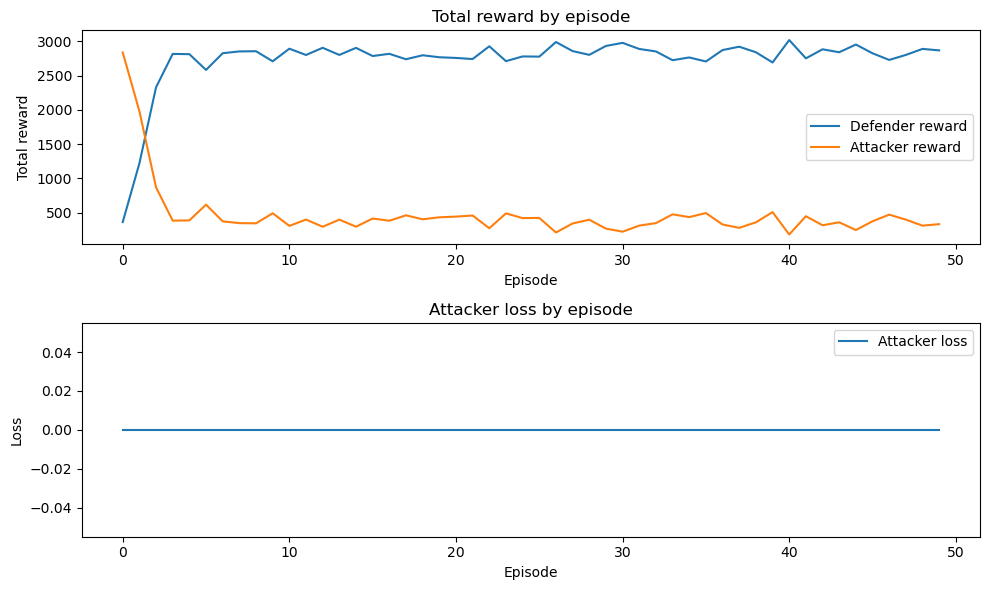

In [14]:
# ----------------------------
# Plot training curves
# ----------------------------
if not os.path.exists('results'):
    os.makedirs('results')

plt.figure(figsize=(10,6))
plt.subplot(211)
plt.plot(np.arange(len(def_reward_chain)), def_reward_chain, label='Defender reward')
plt.plot(np.arange(len(att_reward_chain)), att_reward_chain, label='Attacker reward')
plt.title('Total reward by episode')
plt.xlabel('Episode')
plt.ylabel('Total reward')
plt.legend()

plt.subplot(212)
plt.plot(np.arange(len(att_loss_chain)), att_loss_chain, label='Attacker loss')
plt.title('Attacker loss by episode')
plt.xlabel('Episode')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
#plt.savefig('results/train_adv_cicids2017.png', dpi=300)
plt.show()


# Test and evaluation (CICIDS-2017)


In [15]:
from tensorflow.keras.models import model_from_json

import itertools
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import  confusion_matrix
from imblearn.metrics import geometric_mean_score

In [16]:

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')


In [17]:
# ----------------------------
# TEST (Defender DQN on CICIDS-2017 test split)
# ----------------------------
import os
import json
import numpy as np
import pandas as pd
from tensorflow.keras.models import model_from_json
from sklearn.metrics import classification_report, confusion_matrix

formated_test_path = "formated_test_cicids2017_adv.csv"
data_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/datasets/cicids2017/"
models_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models/"

# Define environment for test (must match the same formatted paths)
env_test = RLenv(
    'test',
    dataset='cicids2017',
    data_dir=data_dir,
    formated_train_path="formated_train_cicids2017_adv.csv",
    formated_test_path=formated_test_path,
    batch_size='full',                 # evaluate on the full test split
    iterations_episode=100,
    include_benign=True,
    force_reformat=False,
    test_size=0.2,
    random_state=42
)

# Load defender DQN model (Q-network)
with open(os.path.join(models_dir, "defender_dqn_model.json"), "r") as f:
    dqn_json = json.load(f)

defender_dqn_model = model_from_json(dqn_json)
defender_dqn_model.load_weights(os.path.join(models_dir, "defender_dqn_model.weights.h5"))

# Pull full test set
states, labels = env_test.get_full()   # states: features; labels: fine-label one-hot columns

# True coarse labels
if labels.shape[0] == 0 or labels.shape[1] == 0:
    raise ValueError(f"Empty test labels: labels shape={labels.shape}. Check include_benign / available CICIDS days / formatted CSVs.")

fine_idx = np.argmax(labels.to_numpy(), axis=1)
fine_labels = labels.columns.to_numpy()[fine_idx]
coarse_labels = np.array([env_test.attack_map.get(lbl, _cicids_label_to_type(lbl)) for lbl in fine_labels])
y_true = np.array([env_test.attack_types.index(t) for t in coarse_labels], dtype=int)

# Predictions: greedy defense action = argmax(Q)
X = states.to_numpy(dtype=np.float32)
Q = defender_dqn_model.predict(X, verbose=0)
y_pred = np.argmax(Q, axis=1)

print("Attack types (classes):", env_test.attack_types)
print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=env_test.attack_types))

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion matrix:\n", cm)


Attack types (classes): ['BENIGN', 'Bot', 'BruteForce', 'DDoS', 'DoS', 'Heartbleed', 'Infiltration', 'PortScan', 'WebAttack']

Classification report:

              precision    recall  f1-score   support

      BENIGN       0.98      0.98      0.98    454620
         Bot       0.00      0.00      0.00       393
  BruteForce       0.99      0.51      0.67      2767
        DDoS       0.99      0.97      0.98     25606
         DoS       0.98      0.86      0.92     50532
  Heartbleed       0.09      1.00      0.16         2
Infiltration       0.00      0.00      0.00         7
    PortScan       0.82      0.99      0.90     31786
   WebAttack       0.00      0.00      0.00       436

    accuracy                           0.97    566149
   macro avg       0.54      0.59      0.51    566149
weighted avg       0.97      0.97      0.97    566149


Confusion matrix:
 [[447271     13      8    247    421     21      5   6634      0]
 [   298      0      0      0      0      0      0     95 

Confusion matrix, without normalization
[[447271     13      8    247    421     21      5   6634      0]
 [   298      0      0      0      0      0      0     95      0]
 [  1359      0   1408      0      0      0      0      0      0]
 [   601      0      0  24726    279      0      0      0      0]
 [  7026      0      0     68  43438      0      0      0      0]
 [     0      0      0      0      0      2      0      0      0]
 [     7      0      0      0      0      0      0      0      0]
 [   269      0      3      4     10      0      0  31500      0]
 [   431      0      0      0      5      0      0      0      0]]


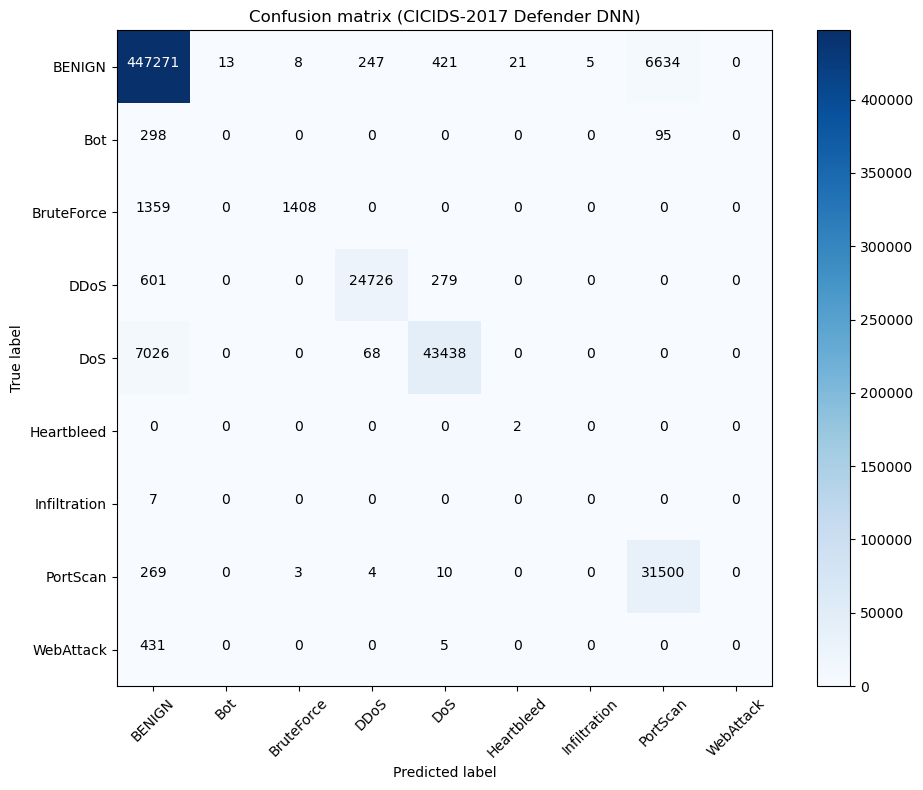

Normalized confusion matrix
[[9.83834851e-01 2.85953104e-05 1.75971141e-05 5.43310897e-04
  9.26048128e-04 4.61924244e-05 1.09981963e-05 1.45924068e-02
  0.00000000e+00]
 [7.58269720e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 2.41730280e-01
  0.00000000e+00]
 [4.91145645e-01 0.00000000e+00 5.08854355e-01 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00]
 [2.34710615e-02 0.00000000e+00 0.00000000e+00 9.65633055e-01
  1.08958838e-02 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00]
 [1.39040608e-01 0.00000000e+00 0.00000000e+00 1.34568194e-03
  8.59613710e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00]
 [1.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e

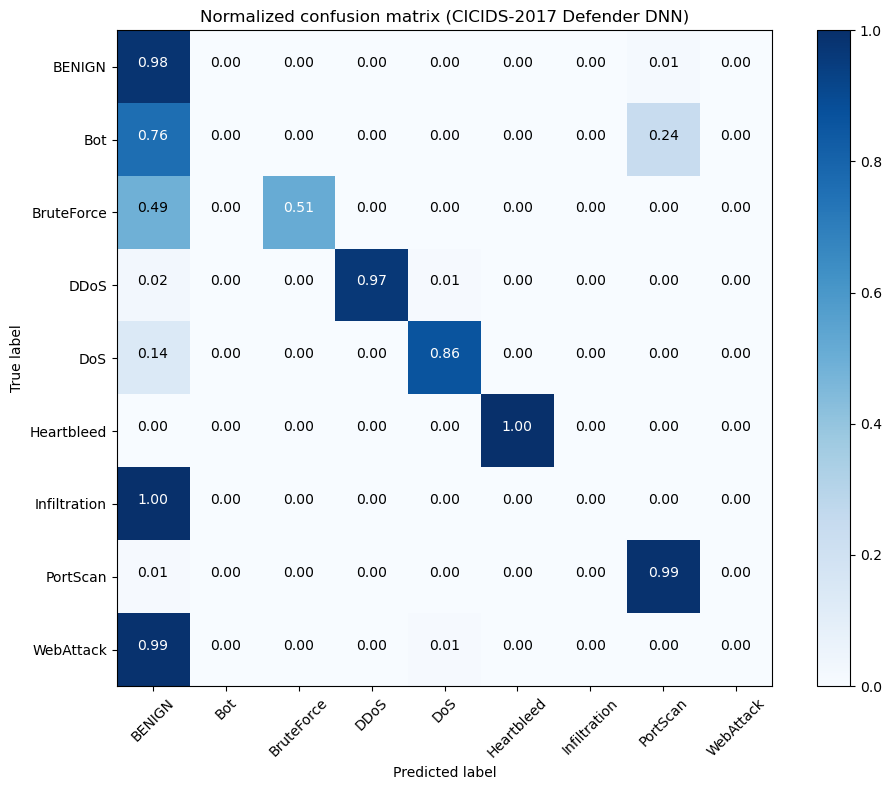

In [18]:
# Plot confusion matrix (normalized + raw)
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))
plot_confusion_matrix(cm, classes=env_test.attack_types, normalize=False,
                      title='Confusion matrix (CICIDS-2017 Defender DNN)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,8))
plot_confusion_matrix(cm, classes=env_test.attack_types, normalize=True,
                      title='Normalized confusion matrix (CICIDS-2017 Defender DNN)')
plt.tight_layout()
plt.show()


In [19]:
# Summary metrics
acc = accuracy_score(y_true, y_pred)
prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
gmean_macro = geometric_mean_score(y_true, y_pred, average='macro')

print(f"Accuracy:          {acc:.4f}"        )
print(f"Precision (macro): {prec_macro:.4f}" )
print(f"Recall    (macro): {rec_macro:.4f}"  )
print(f"F1        (macro): {f1_macro:.4f}"   )
print(f"G-Mean    (macro): {gmean_macro:.4f}")


Accuracy:          0.9686
Precision (macro): 0.5392
Recall    (macro): 0.5899
F1        (macro): 0.5119
G-Mean    (macro): 0.7636


In [ ]:
# # ----------------------------
# # 6) Explainability for the defender (SHAP + SAGE)
# # ----------------------------
# # SHAP (recommended): uses a small background set to keep runtime manageable
# try:
#     import shap

#     # background and evaluation samples
#     background = X_tr[np.random.choice(X_tr.shape[0], size=min(256, X_tr.shape[0]), replace=False)]
#     sample = X_val[:min(512, X_val.shape[0])]

#     explainer = shap.Explainer(defender_dnn.model, background)
#     shap_values = explainer(sample)

#     # Global importance (bar)
#     shap.plots.bar(shap_values, max_display=20)
#     # Local/summary (beeswarm)
#     shap.plots.beeswarm(shap_values, max_display=20)

# except Exception as e:
#     print(f"SHAP explainability skipped (install shap or check TF/Keras compatibility): {e}")


In [ ]:
# ----------------------------
# Explainability for the Defender (DQN) using SAGE (optional)
# ----------------------------
# NOTE: Requires `sage-importance` (pip install sage-importance)
# This explains the defender's Q-network outputs (converted to probabilities via softmax).

import numpy as np
import sage

# Use the model from the TEST cell if present; otherwise load it
try:
    _model = defender_dqn_model
except NameError:
    import os, json
    from tensorflow.keras.models import model_from_json
    models_dir = "C:/Users/Curtis Rookard/OneDrive/Desktop/Research/Research Projects/Asymmetric_RL_Agents/models/"
    with open(os.path.join(models_dir, "defender_dqn_model.json"), "r") as f:
        dqn_json = json.load(f)
    _model = model_from_json(dqn_json)
    _model.load_weights(os.path.join(models_dir, "defender_dqn_model.weights.h5"))

def _softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    ez = np.exp(z)
    return ez / (np.sum(ez, axis=1, keepdims=True) + 1e-12)

# Prediction function: returns probs over defender actions
def pred_fn(x):
    x = np.asarray(x, dtype=np.float32)
    q = _model.predict(x, verbose=0)
    return _softmax(q)

# Build labels: use the defender's greedy action as the "target" class for SAGE
# (This yields global feature importance for the chosen defense action.)
    # Use a pool of feature vectors
if "X_tr" in globals():
    X_pool = X_tr
    feature_names_src = globals().get("X_train", None)
elif "states" in globals():
    # from the TEST cell
    X_pool = states.to_numpy(dtype=np.float32) if hasattr(states, "to_numpy") else np.asarray(states, dtype=np.float32)
    feature_names_src = states
else:
    raise ValueError("No feature matrix found for SAGE. Run the training or TEST cell first.")

n_pool = X_pool.shape[0]
idxs = np.random.choice(n_pool, size=min(2000, n_pool), replace=False)
X_sage = X_pool[idxs]

y_sage = np.argmax(pred_fn(X_sage), axis=1)

# Background set for the imputer
bg = X_pool[np.random.choice(n_pool, size=min(512, n_pool), replace=False)]

imputer = sage.MarginalImputer(pred_fn, bg)
estimator = sage.PermutationEstimator(imputer, loss="cross entropy")
imps = estimator(X_sage, y_sage, n_permutations=64)

# Feature names
try:
    feature_names = list(feature_names_src.columns)
except Exception:
    feature_names = [f"f{i}" for i in range(X_sage.shape[1])]

imps.plot(feature_names, max_features=20, title="SAGE Global Importance for Defender DQN (Q-network)")

